# TP6 — Bootstrap and Asymptotic Confidence Intervals

**Financial Econometrics · Prof. Olivier Scaillet · TA Ernest Ivanaj**  

## Overview

This notebook investigates the construction and performance of confidence intervals for the Sharpe ratio, comparing asymptotic methods with bootstrap procedures under both independent and serially dependent observations.

The analysis follows the original sequence of the TP6 exercise sheet, with an additional section examining the implications of serial dependence for bootstrap inference.

The notebook is organized into four sections:

1. **The Delta Method** — Simulation of returns, estimation of the Sharpe ratio, and construction of an asymptotic confidence interval using the Delta Method.
2. **Bootstrap Confidence Interval** — Implementation of IID bootstrap resampling, construction of the basic bootstrap confidence interval, and investigation of the effect of sample size.
3. **Dependent Data: The Block Bootstrap** — Implementation of the non-overlapping block bootstrap, construction of confidence intervals, and repeated comparisons with the IID bootstrap.
4. **Bonus: Bootstrap under AR(1) Dependence** — Simulation of an AR(1) process, analysis of its theoretical and empirical ACF and PACF, and comparison of IID and block bootstrap confidence intervals under serial dependence.

## Notation and Experimental Design

| Symbol | Meaning | Baseline value |
|:--|:--|--:|
| $T$ | Number of observations in a single dataset | $100$ |
| $B$ | Number of bootstrap resamples conditional on a single dataset | $2{,}000$ |
| $M$ | Number of independently generated Monte Carlo datasets in repeated experiments | $100$ |
| $\mu$ | Population mean | $1$ |
| $\sigma^2$ | Population variance | $16$ |
| $\ell$ | Block length | $10$ |
| $k=T/\ell$ | Number of non-overlapping blocks | $10$ |

### Simulation Framework

A distinction is maintained between bootstrap resampling and Monte Carlo replication throughout the analysis.

The **bootstrap procedure** generates $B=2{,}000$ resamples conditional on a single observed dataset of size $T=100$, as specified in the exercise sheet.

The **Monte Carlo experiments**, introduced for comparative purposes, generate $M=100$ independent datasets. These repetitions allow us to assess the sampling variability and empirical performance of the different confidence interval procedures.

The baseline parameters are kept consistent across sections to facilitate comparisons, while specific assumptions are modified when investigating the effects of sample size and serial dependence.



## 0. Common setup

We use **NumPy** for simulations and **Matplotlib** for figures. `ggplot` is the starting style, with simple white backgrounds and restrained colors. No external datasets or nonstandard statistical packages are required.

Separate random-number generators ensure that changing an exploratory figure does **not** silently change the principal confidence intervals.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from statistics import NormalDist

# Keep the course's requested base style, then simplify the appearance.
plt.style.use("ggplot")
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "0.25",
    "axes.labelcolor": "0.15",
    "text.color": "0.15",
    "xtick.color": "0.25",
    "ytick.color": "0.25",
    "grid.color": "0.87",
    "grid.alpha": 0.6,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.dpi": 115,
    "savefig.dpi": 150,
    "axes.titleweight": "medium",
})

# A consistent palette for all sections.
C_DARK = "#25364a"
C_RED = "#b34343"
C_BLUE = "#78a9c9"
C_GRAY = "#a0a6ad"
C_GREEN = "#477f71"

T = 100                  # Number of observations in the original sample
B = 2000                 # Bootstrap repetitions for one fixed dataset
MU = 1.0                 # True mean monthly return, in percent
SIGMA = 4.0              # True standard deviation (variance = 16)
V = SIGMA**2
L = 10                   # Length of each non-overlapping block
ALPHA = 0.05
Z = NormalDist().inv_cdf(1 - ALPHA / 2)
TRUE_SR = MU / SIGMA     # Risk-free rate is assumed to be zero

rng_data = np.random.default_rng(123)
rng_iid = np.random.default_rng(456)
rng_block = np.random.default_rng(457)

print(f"T={T}, B={B}, mu={MU}, variance={V:.0f}, l={L}")
print(f"Theoretical Sharpe ratio = {TRUE_SR:.4f}; z_0.975 = {Z:.4f}")

T=100, B=2000, mu=1.0, variance=16, l=10
Theoretical Sharpe ratio = 0.2500; z_0.975 = 1.9600



### Exercise 1.1 — Simulating Gaussian Returns

We generate a sample of $T=100$ independent observations from the Gaussian distribution:

$$
X_t \sim \mathcal{N}(1,16).
$$

These observations represent monthly percentage stock returns, with population mean $\mu=1$ and standard deviation $\sigma=4$.

The simulated sample will be used throughout the following exercises.


---
# 1. The Delta Method

The Delta Method converts an asymptotic distribution for a parameter vector into one for a **differentiable nonlinear function** of that vector. We first establish the general multivariate result and only then specialize to the IID Gaussian model required by TP6.

## Exercise 1.1 — Simulate $T=100$ returns from $N(1,16)$

Assume that monthly percentage returns are IID:

$$
X_t\overset{\mathrm{iid}}\sim N(\mu,\sigma^2),\qquad
\mu=1,\quad\sigma^2=16,\qquad t=1,\ldots,T.
$$

The risk-free rate is set to zero throughout.


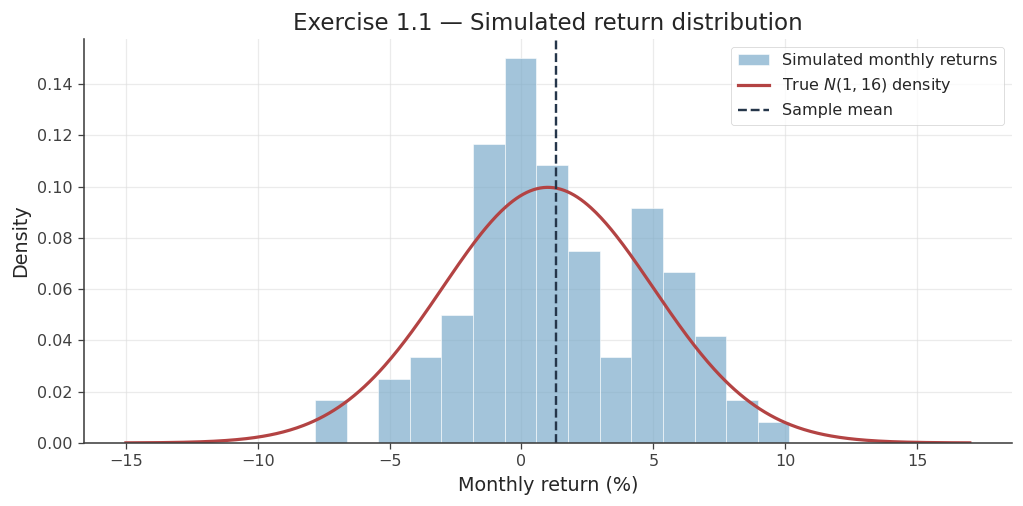

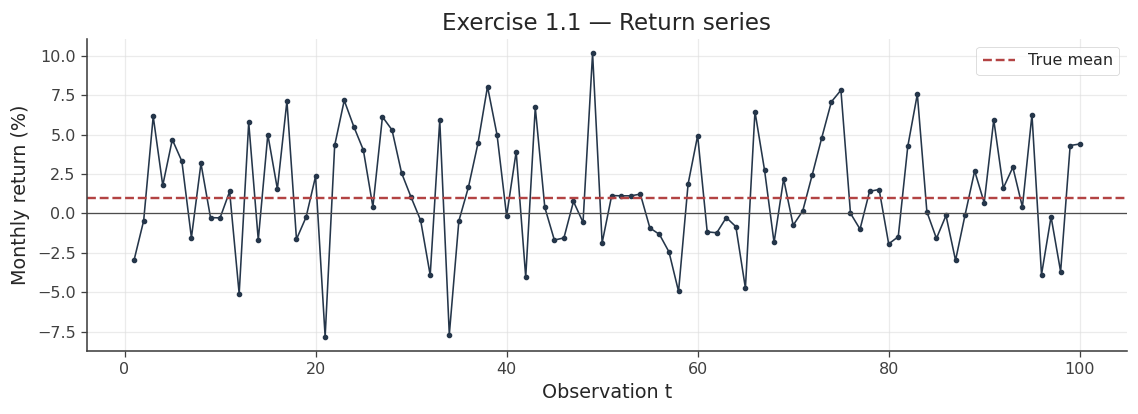

In [2]:
# Generate exactly one original dataset, shared by all first three sections.
x = rng_data.normal(loc=MU, scale=SIGMA, size=T)

# Histogram against the known population density.
grid = np.linspace(min(x.min(), MU - 4*SIGMA),
                   max(x.max(), MU + 4*SIGMA), 500)
normal_density = np.exp(-0.5*((grid - MU)/SIGMA)**2) / (SIGMA*np.sqrt(2*np.pi))

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(x, bins=15, density=True, alpha=0.68, color=C_BLUE,
        edgecolor="white", label="Simulated monthly returns")
ax.plot(grid, normal_density, color=C_RED, lw=2,
        label=r"True $N(1,16)$ density")
ax.axvline(np.mean(x), color=C_DARK, ls="--", label="Sample mean")
ax.set(title="Exercise 1.1 — Simulated return distribution",
       xlabel="Monthly return (%)", ylabel="Density")
ax.legend()
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 3.7))
ax.plot(np.arange(1, T+1), x, color=C_DARK, lw=1, marker="o", ms=2.5)
ax.axhline(MU, color=C_RED, ls="--", lw=1.5, label="True mean")
ax.axhline(0, color="0.3", lw=0.8)
ax.set(title="Exercise 1.1 — Return series", xlabel="Observation t",
       ylabel="Monthly return (%)")
ax.legend()
plt.tight_layout()
plt.show()

## Exercise 1.2 — Estimate parameters and the Sharpe ratio

Define the population parameter vector with the **variance** as its second element:

$$
\theta=\begin{pmatrix}\mu\\v\end{pmatrix},\qquad
v=\sigma^2,\qquad
\widehat\theta=\begin{pmatrix}\widehat\mu\\\widehat v\end{pmatrix}.
$$

We use the maximum-likelihood (denominator-$T$) estimates:

$$
\widehat\mu=\frac1T\sum_{t=1}^T X_t,\qquad
\widehat v=\frac1T\sum_{t=1}^T(X_t-\widehat\mu)^2,
\qquad \widehat\sigma=\sqrt{\widehat v}.
$$

The (unannualized) Sharpe ratio is a nonlinear function of $\theta$:

$$
SR=g(\theta)=\frac{\mu}{\sqrt v},\qquad
\widehat{SR}=g(\widehat\theta)=\frac{\widehat\mu}{\sqrt{\widehat v}}.
$$

Since our dataset consists of monthly returns, both the estimated mean and standard deviation refer to the monthly frequency. Consequently, we report the monthly (non-annualized) Sharpe ratio, consistently with the parameter defined in the exercise.

In [3]:
def sharpe_ratio(sample):
    """Monthly Sharpe ratio with risk-free return zero; ddof=0 throughout."""
    sample = np.asarray(sample)
    return np.mean(sample) / np.std(sample, ddof=0)

mu_hat = np.mean(x)
v_hat = np.var(x, ddof=0)
sigma_hat = np.sqrt(v_hat)
sr_hat = sharpe_ratio(x)

print(f"Estimated mean             = {mu_hat:.6f}")
print(f"Estimated variance         = {v_hat:.6f}")
print(f"Estimated std. deviation   = {sigma_hat:.6f}")
print(f"Estimated Sharpe ratio     = {sr_hat:.6f}")
print(f"True Sharpe ratio          = {TRUE_SR:.6f}")

Estimated mean             = 1.327659
Estimated variance         = 12.816444
Estimated std. deviation   = 3.580006
Estimated Sharpe ratio     = 0.370854
True Sharpe ratio          = 0.250000


## Exercise 1.3 — Derive the 95% Delta Method interval

### Step 1. Joint central limit theorem (general formulation)

For a regular estimator and a suitable covariance matrix $\Sigma$:

$$
\sqrt{T}(\widehat\theta-\theta)
\xrightarrow{d}N(0,\Sigma),\qquad
\Sigma=\begin{pmatrix}
\Sigma_{11}&\Sigma_{12}\\
\Sigma_{12}&\Sigma_{22}
\end{pmatrix}.
$$

The notation $\xrightarrow{d}$ denotes convergence **in distribution**. The factor $\sqrt T$ is the estimator's convergence rate: equivalently, $\widehat\theta-\theta=O_p(T^{-1/2})$. It is **not** a statement that the random estimation error is deterministically equal to $T^{-1/2}$.

### Step 2. First-order Taylor expansion

If $g$ is continuously differentiable in a neighborhood of $\theta$ (with $v>0$), then

$$
g(\widehat\theta)-g(\theta)
=\nabla g(\theta)^\top(\widehat\theta-\theta)
+o_p(\|\widehat\theta-\theta\|).
$$

Multiplying by $\sqrt T$ and applying the CLT and Slutsky's theorem gives the **multivariate Delta Method**:

$$
\sqrt T\bigl(g(\widehat\theta)-g(\theta)\bigr)
\xrightarrow{d}N\!\left(0,
\nabla g(\theta)^\top\Sigma\nabla g(\theta)\right).
$$

### Step 3. Gradient / Jacobian of the Sharpe ratio

For $g(\mu,v)=\mu v^{-1/2}$:

$$
\frac{\partial g}{\partial\mu}=v^{-1/2}=\frac1\sigma,
\qquad
\frac{\partial g}{\partial v}
=-\frac{\mu}{2v^{3/2}}=-\frac{\mu}{2\sigma^3}.
$$

Thus, writing $d=\nabla g(\theta)$,

$$
d=\begin{pmatrix}
1/\sqrt v\\
-\mu/(2v^{3/2})
\end{pmatrix}.
$$

### Step 4. **Explicit variance–covariance matrix multiplication**

The asymptotic variance of $\sqrt T(\widehat{SR}-SR)$ is the scalar quadratic form

$$
V_{SR}=d^\top\Sigma d
=\begin{pmatrix}\dfrac1{\sqrt v}&-\dfrac\mu{2v^{3/2}}\end{pmatrix}
\begin{pmatrix}\Sigma_{11}&\Sigma_{12}\\\Sigma_{12}&\Sigma_{22}\end{pmatrix}
\begin{pmatrix}\dfrac1{\sqrt v}\\-\dfrac\mu{2v^{3/2}}\end{pmatrix}.
$$

Expanding **all three terms**, including the covariance:

$$
\boxed{\displaystyle
V_{SR}=\frac{\Sigma_{11}}{v}
-\frac{\mu\Sigma_{12}}{v^2}
+\frac{\mu^2\Sigma_{22}}{4v^3}}
$$

Consequently, $\operatorname{Var}(\widehat{SR})\approx V_{SR}/T$, and its **standard error** is the square root $\sqrt{V_{SR}/T}$. This is why the denominator of a standardized statistic has a square root.

### Step 5. Specialize to IID Gaussian returns

For a Gaussian sample, with $\widehat v=T^{-1}\sum(X_t-\widehat\mu)^2$, we have

$$
\sqrt T\begin{pmatrix}\widehat\mu-\mu\\\widehat v-v\end{pmatrix}
\xrightarrow{d}N\!\left[
\begin{pmatrix}0\\0\end{pmatrix},
\underbrace{\begin{pmatrix}v&0\\0&2v^2\end{pmatrix}}_{\Sigma_{\mathrm{Gaussian}}}
\right].
$$

The mean and variance estimators are asymptotically uncorrelated; the relevant Gaussian fourth moment is $E[(X-\mu)^4]=3v^2$. Hence

$$
\operatorname{Var}\bigl((X-\mu)^2\bigr)=3v^2-v^2=2v^2.
$$

Substitute $\Sigma_{11}=v$, $\Sigma_{12}=0$, $\Sigma_{22}=2v^2$:

$$
V_{SR}=\frac{v}{v}+\frac{\mu^2(2v^2)}{4v^3}
=1+\frac{\mu^2}{2v}
=\boxed{1+\tfrac12 SR^2}.
$$

Finally, substitute $\widehat\theta$ for $\theta$ (Slutsky's theorem):

$$
\boxed{\widehat{SE}_{\Delta}=
\sqrt{\frac{1+\frac12\widehat{SR}^{\,2}}{T}}},
\qquad
\boxed{CI_{\Delta,95\%}=
\widehat{SR}\pm z_{0.975}\widehat{SE}_{\Delta}}.
$$

A 95% **confidence interval** concerns the repeated-sampling performance of this procedure, not a 95% probability that the fixed true parameter belongs to a particular already-computed interval.


In [4]:
def gaussian_delta_ci(sample, alpha=0.05):
    """Gaussian IID Delta CI, explicitly using the 2-by-2 covariance matrix."""
    n = len(sample)
    m_hat = np.mean(sample)
    v_hat_local = np.var(sample, ddof=0)
    sr = m_hat / np.sqrt(v_hat_local)

    # Jacobian d = (partial SR / partial mu, partial SR / partial v)'.
    gradient = np.array([1 / np.sqrt(v_hat_local),
                         -m_hat / (2 * v_hat_local**1.5)])

    # Covariance of sqrt(n) * (theta_hat - theta): not Cov(theta_hat) itself.
    sigma_asym = np.diag([v_hat_local, 2 * v_hat_local**2])

    # Delta quadratic form: d' Sigma d, then divide by sample size n.
    asym_variance = gradient @ sigma_asym @ gradient
    se = np.sqrt(asym_variance / n)
    z_alpha = NormalDist().inv_cdf(1 - alpha / 2)
    ci = np.array([sr - z_alpha*se, sr + z_alpha*se])
    return sr, ci, se, asym_variance, gradient, sigma_asym

sr_delta, ci_delta, se_delta, v_delta, gradient_hat, Sigma_hat = gaussian_delta_ci(x)

# Algebraic cross-check against the simplified formula used in the original code.
se_simplified = np.sqrt((1 + 0.5*sr_hat**2) / T)
assert np.allclose(se_delta, se_simplified)

print("Estimated Jacobian d_hat:", np.round(gradient_hat, 6))
print("Estimated asymptotic covariance matrix Sigma_hat:\n", np.round(Sigma_hat, 5))
print(f"d_hat' Sigma_hat d_hat = {v_delta:.6f}")
print(f"Delta standard error    = {se_delta:.6f}")
print(f"Delta 95% CI            = [{ci_delta[0]:.6f}, {ci_delta[1]:.6f}]")

Estimated Jacobian d_hat: [ 0.279329 -0.014468]
Estimated asymptotic covariance matrix Sigma_hat:
 [[ 12.81644   0.     ]
 [  0.      328.52249]]
d_hat' Sigma_hat d_hat = 1.068766
Delta standard error    = 0.103381
Delta 95% CI            = [0.168231, 0.573477]


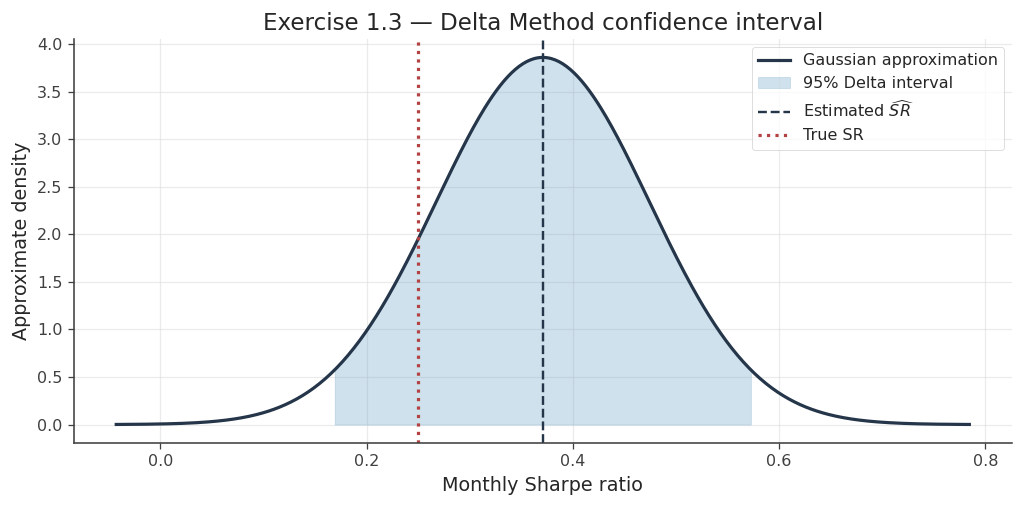

In [5]:
# Visualize the normal approximation for the estimated Sharpe ratio.
grid_sr = np.linspace(sr_hat - 4*se_delta, sr_hat + 4*se_delta, 450)
dens_sr = np.exp(-0.5*((grid_sr-sr_hat)/se_delta)**2) / (se_delta*np.sqrt(2*np.pi))

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(grid_sr, dens_sr, color=C_DARK, lw=2, label="Gaussian approximation")
ax.fill_between(grid_sr, 0, dens_sr,
                where=(grid_sr >= ci_delta[0]) & (grid_sr <= ci_delta[1]),
                color=C_BLUE, alpha=0.35, label="95% Delta interval")
ax.axvline(sr_hat, color=C_DARK, ls="--", label=r"Estimated $\widehat{SR}$")
ax.axvline(TRUE_SR, color=C_RED, ls=":", lw=2, label="True SR")
ax.set(title="Exercise 1.3 — Delta Method confidence interval",
       xlabel="Monthly Sharpe ratio", ylabel="Approximate density")
ax.legend()
plt.tight_layout()
plt.show()

### Technical note — rates of convergence and stochastic remainder terms

A sequence $Z_T$ is **bounded in probability**, $Z_T=O_p(1)$, if for every $\varepsilon>0$ there is a finite constant $K_\varepsilon$ such that, for all sufficiently large $T$,

$$P(|Z_T|>K_\varepsilon)<\varepsilon.$$

A sequence is **negligible in probability**, $Z_T=o_p(1)$, when $Z_T\xrightarrow{p}0$, i.e., for every $\varepsilon>0$,

$$P(|Z_T|>\varepsilon)\longrightarrow0.$$

A root-$T$ CLT implies $\sqrt T(\widehat\theta-\theta)=O_p(1)$ and thus $\widehat\theta-\theta=O_p(T^{-1/2})$. The Delta expansion's remainder satisfies $\sqrt T\,R_T=o_p(1)$, so it disappears in the limiting distribution.

This $T^{-1/2}$ **rate** tells us how fast uncertainty shrinks; it does not describe the shape of the limiting distribution, which is a separate statement supplied by the CLT and the Delta Method.


### Transition: why look beyond the Delta Method?

We have an **analytical** confidence interval because the Gaussian-IID assumption delivers an explicit covariance matrix $\Sigma$. If the finite-sample distribution of a nonlinear estimator is asymmetric, however, a symmetric normal interval may be inaccurate. The **IID bootstrap** estimates that sampling distribution by resampling from the observed data.

The next section still assumes **independent returns**; serial dependence requires a different resampling scheme, developed in Section 3.


---
# 2. Bootstrap Confidence Interval

## Exercise 2.1 — Generate $B=2{,}000$ ordinary bootstrap samples

### The statistical idea

Let $F$ be the unknown distribution generating the original IID observations. The **empirical distribution** is

$$
\widehat F_T(x)=\frac1T\sum_{t=1}^T\mathbf{1}\{X_t\le x\}.
$$

The ordinary **nonparametric IID bootstrap** draws, *conditional on the original data*,

$$
X_1^{*(b)},\ldots,X_T^{*(b)}\overset{\mathrm{iid}}\sim\widehat F_T,
\qquad b=1,\ldots,B.
$$

Each draw is one of the original observations, selected **with replacement**, so an observation may appear multiple times or not at all. For each bootstrap dataset:

$$
\widehat{SR}^{*(b)}=
\frac{\widehat\mu^{*(b)}}{\widehat\sigma^{*(b)}}.
$$

Under regularity and IID sampling, the conditional distribution of
$\sqrt T(\widehat{SR}^{*}-\widehat{SR})$ consistently approximates the sampling distribution of $\sqrt T(\widehat{SR}-SR)$.

**Crucial distinction:** $T=100$ is the number of observations **within each** resample; $B=2000$ is how many such resamples are generated. No new observations from $N(1,16)$ are generated inside the bootstrap.

To make the resampling procedure easier to follow, the **table below shows a small example**. Each resample has the same size as the original sample, but **observations are drawn with replacement.**

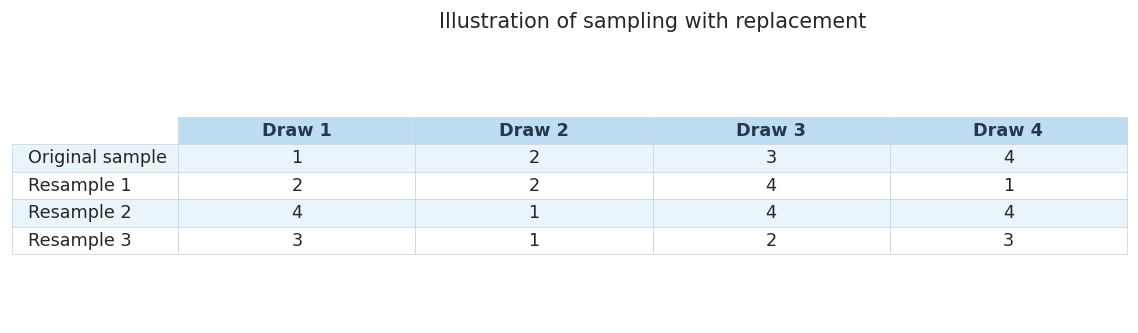

In [6]:
small_data = np.array([1, 2, 3, 4])
small_samples = np.array([
    [2, 2, 4, 1],
    [4, 1, 4, 4],
    [3, 1, 2, 3]
])

table_values = np.vstack([small_data, small_samples])

fig, ax = plt.subplots(figsize=(10, 3))
ax.axis("off")

table = ax.table(
    cellText=table_values,
    rowLabels=[
        "Original sample",
        "Resample 1",
        "Resample 2",
        "Resample 3"
    ],
    colLabels=["Draw 1", "Draw 2", "Draw 3", "Draw 4"],
    cellLoc="center",
    loc="center"
)

table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1, 1.4)

for (row, col), cell in table.get_celld().items():
    cell.set_edgecolor("#C9D6E2")
    if row == 0:
        cell.set_facecolor("#BFDDF2")
        cell.set_text_props(weight="bold", color="#26384A")
    else:
        cell.set_facecolor("#EAF4FB" if row % 2 else "white")

ax.set_title(
    "Illustration of sampling with replacement",
    fontsize=13,
    pad=14
)

plt.tight_layout()
plt.show()

Each bootstrap sample is constructed by drawing observations **with replacement** from the original dataset, preserving the same sample size. Consequently, some observations may be selected multiple times, while others may not be selected at all.

The table above provides a simplified illustration of this procedure. In the actual experiment, each bootstrap sample contains **T = 100 observations**, matching the size of the original dataset.

In [7]:
def iid_bootstrap_draws(sample, rng, B=2000):
    """Generate B Sharpe estimates by resampling individual data points."""
    sample = np.asarray(sample)
    n = len(sample)

    # Each row is a different bootstrap dataset of length n.
    indices = rng.integers(0, n, size=(B, n))
    resamples = sample[indices]

    # Axis 1: calculate the statistic separately for each bootstrap dataset.
    sr_draws = (np.mean(resamples, axis=1)
                / np.std(resamples, axis=1, ddof=0))
    return sr_draws

sr_iid_draws = iid_bootstrap_draws(x, rng_iid, B=B)
assert sr_iid_draws.shape == (B,)

print(f"Number of bootstrap estimates: {len(sr_iid_draws)}")
print(f"Mean bootstrap Sharpe ratio:  {sr_iid_draws.mean():.6f}")
print(f"Bootstrap std. deviation:    {sr_iid_draws.std(ddof=1):.6f}")

Number of bootstrap estimates: 2000
Mean bootstrap Sharpe ratio:  0.371766
Bootstrap std. deviation:    0.103501


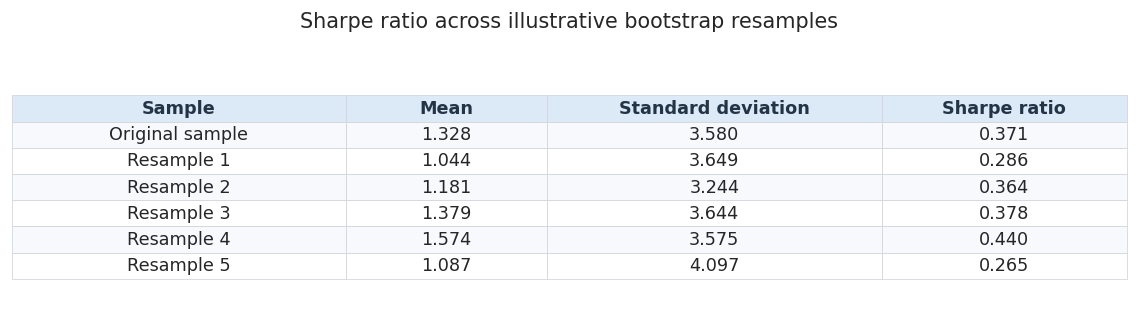

In [8]:
presentation_rng = np.random.default_rng(2026)

example_indices = presentation_rng.integers(
    0, len(x), size=(5, len(x))
)
example_samples = x[example_indices]

example_means = example_samples.mean(axis=1)
example_sds = example_samples.std(axis=1, ddof=0)
example_srs = example_means / example_sds

rows = [
    ["Original sample", f"{np.mean(x):.3f}",
     f"{np.std(x, ddof=0):.3f}", f"{sr_hat:.3f}"]
]

for i in range(5):
    rows.append([
        f"Resample {i + 1}",
        f"{example_means[i]:.3f}",
        f"{example_sds[i]:.3f}",
        f"{example_srs[i]:.3f}"
    ])

fig, ax = plt.subplots(figsize=(10, 3))
ax.axis("off")

table = ax.table(
    cellText=rows,
    colLabels=["Sample", "Mean", "Standard deviation", "Sharpe ratio"],
    cellLoc="center",
    loc="center",
    colWidths=[0.30, 0.18, 0.30, 0.22]
)

table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1, 1.35)

for (row, col), cell in table.get_celld().items():
    cell.set_edgecolor("#D1D5DB")
    if row == 0:
        cell.set_facecolor("#DCEAF7")
        cell.set_text_props(weight="bold", color="#243447")
    else:
        cell.set_facecolor("#F7F9FC" if row % 2 else "white")

ax.set_title(
    "Sharpe ratio across illustrative bootstrap resamples",
    fontsize=13,
    pad=16
)

plt.tight_layout()
plt.show()

Each resample gives a different estimate of the Sharpe ratio because observations are drawn with replacement from the original sample\. These five resamples are only illustrative, in fact the full bootstrap distribution is based on 2,000 resamples\.

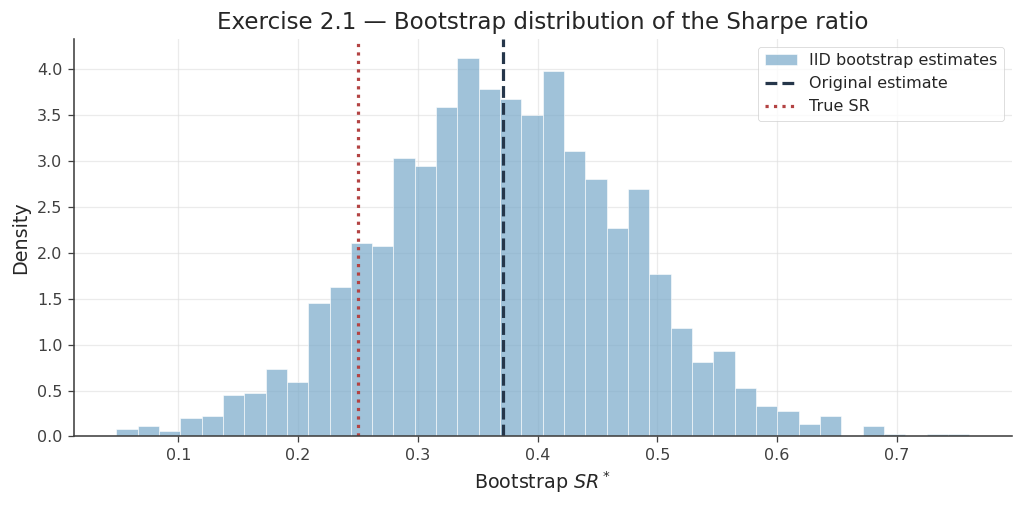

In [9]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(sr_iid_draws, bins=40, density=True, alpha=0.7, color=C_BLUE,
        edgecolor="white", label="IID bootstrap estimates")
ax.axvline(sr_hat, color=C_DARK, ls="--", lw=2, label="Original estimate")
ax.axvline(TRUE_SR, color=C_RED, ls=":", lw=2, label="True SR")
ax.set(title="Exercise 2.1 — Bootstrap distribution of the Sharpe ratio",
       xlabel=r"Bootstrap $SR^*$", ylabel="Density")
ax.legend()
plt.tight_layout()
plt.show()

***Graph interpretation:*** the histogram shows how the estimated Sharpe ratio varies across the bootstrap resamples\. The vertical lines mark the original sample estimate and because the data are simulated, the known true Sharpe ratio\.

### Why the IID bootstrap approximates the sampling distribution (formal sketch)

Define the centered influence vector for the parameter estimator:

$$
\psi_t=\begin{pmatrix}X_t-\mu\\(X_t-\mu)^2-v\end{pmatrix}.
$$

For IID observations with finite fourth moment, and under the conditions of the multivariate CLT,

$$
\sqrt T(\widehat\theta-\theta)
=\frac{1}{\sqrt T}\sum_{t=1}^T\psi_t+o_p(1)
\xrightarrow{d}N(0,\Sigma),
\qquad \Sigma=E[\psi_t\psi_t^\top].
$$

**Conditional bootstrap argument:** having observed $x_1,\ldots,x_T$, let $E^*[\cdot]$ and $\operatorname{Var}^*[\cdot]$ refer to draws from the empirical law $\widehat F_T$. We have exactly

$$
E^*[X_t^*]=\widehat\mu,\qquad
\operatorname{Var}^*[X_t^*]=\widehat v.
$$

Let $\widehat\psi_t^*$ denote the mean/variance influence vector evaluated at the original sample estimates. The bootstrap estimates satisfy the first-order expansion

$$
\sqrt T(\widehat\theta^*-\widehat\theta)
=\frac1{\sqrt T}\sum_{t=1}^T\widehat\psi_t^*+o_{P^*}(1).
$$

The conditional CLT and consistency of the empirical covariance then imply, **in probability** with respect to the original sample,

$$
\mathcal L^*\left(\sqrt T(\widehat\theta^*-\widehat\theta)\right)
\Longrightarrow N(0,\Sigma).
$$

Finally apply the same differentiable function $g(\mu,v)=\mu/\sqrt v$ and its sample gradient $\widehat d$:

$$
\sqrt T(\widehat{SR}^{*}-\widehat{SR})
=\widehat d^\top\sqrt T(\widehat\theta^*-\widehat\theta)
+o_{P^*}(1)
\Longrightarrow N(0,d^\top\Sigma d).
$$

This is the theoretical reason the conditional centered bootstrap distribution can approximate the true centered sampling distribution. It is an **asymptotic** justification, not an assertion that the two finite-sample distributions are identical.


## Exercise 2.2 — Derive the 95% **basic bootstrap** confidence interval

The TP specifically asks for a **basic/reversed-percentile interval**, not the ordinary percentile interval. Let $q^*_{\alpha}$ denote the empirical $\alpha$-quantile of the $B$ bootstrap Sharpe estimates.

**Step 1.** Work with the centered estimation error, conditional on the observed sample:

$$
\widehat{SR}^{*}-\widehat{SR}.
$$

By construction, its estimated middle 95% has endpoints $q^*_{0.025}-\widehat{SR}$ and $q^*_{0.975}-\widehat{SR}$:

$$
P^*\!\left(q^*_{0.025}-\widehat{SR}
\le\widehat{SR}^{*}-\widehat{SR}
\le q^*_{0.975}-\widehat{SR}\right)\approx0.95.
$$

**Step 2.** Under bootstrap consistency, the centered bootstrap error approximates the true sampling error:

$$
\widehat{SR}^{*}-\widehat{SR}
\quad\text{approximates}\quad
\widehat{SR}-SR.
$$

This statement is **asymptotic and distributional**, not an identity for individual resamples.

**Step 3.** Replace the bootstrap error with the actual estimation error and solve for the unknown population parameter $SR$:

$$
q^*_{0.025}-\widehat{SR}
\lesssim\widehat{SR}-SR
\lesssim q^*_{0.975}-\widehat{SR},
$$

$$
\boxed{CI_{\mathrm{IID},95\%}=
\left[2\widehat{SR}-q^*_{0.975},\;
2\widehat{SR}-q^*_{0.025}\right]}.
$$

The order of the quantiles is **reversed**: subtracting a high quantile gives the **lower** endpoint.


In [10]:
def basic_bootstrap_ci(original_estimate, bootstrap_estimates, alpha=0.05):
    """Basic (reverse-percentile) bootstrap confidence interval."""
    q_low, q_high = np.quantile(bootstrap_estimates,
                                [alpha / 2, 1 - alpha / 2])
    return np.array([2*original_estimate-q_high,
                     2*original_estimate-q_low])

ci_iid = basic_bootstrap_ci(sr_hat, sr_iid_draws)
errors_iid = sr_iid_draws - sr_hat

print(f"Delta 95% CI       : {np.round(ci_delta, 6)}")
print(f"IID bootstrap 95% CI: {np.round(ci_iid, 6)}")
print(f"Delta CI width      : {np.ptp(ci_delta):.6f}")
print(f"IID CI width        : {np.ptp(ci_iid):.6f}")

Delta 95% CI       : [0.168231 0.573477]
IID bootstrap 95% CI: [0.17033  0.578556]
Delta CI width      : 0.405247
IID CI width        : 0.408226


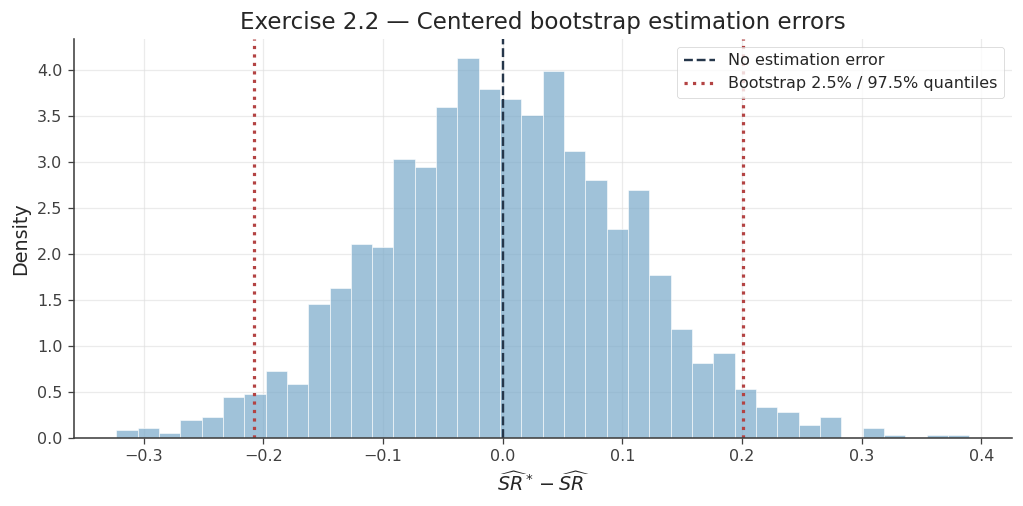

In [11]:
# Centering isolates estimation error, the quantity underlying a basic CI.
q_error_low, q_error_high = np.quantile(errors_iid, [0.025, 0.975])
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(errors_iid, bins=40, density=True, alpha=0.7,
        color=C_BLUE, edgecolor="white")
ax.axvline(0, color=C_DARK, ls="--", lw=1.5, label="No estimation error")
ax.axvline(q_error_low, color=C_RED, ls=":", lw=2,
           label="Bootstrap 2.5% / 97.5% quantiles")
ax.axvline(q_error_high, color=C_RED, ls=":", lw=2)
ax.set(title="Exercise 2.2 — Centered bootstrap estimation errors",
       xlabel=r"$\widehat{SR}^*-\widehat{SR}$", ylabel="Density")
ax.legend()
plt.tight_layout()
plt.show()

***Graph interpretation:*** each bootstrap error is calculated as the bootstrap Sharpe ratio minus the original sample estimate\. The histogram shows the distribution of these errors relative to zero\. The 2\.5th and 97\.5th percentiles of the bootstrap errors are used to construct the basic 95% confidence interval\.

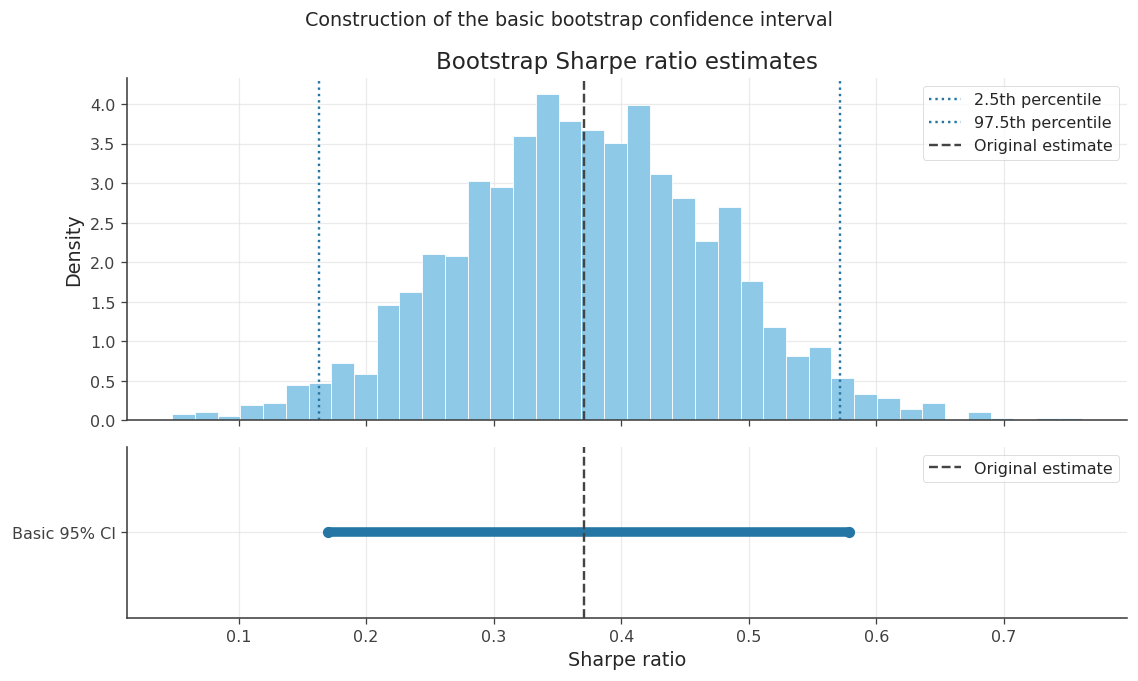

In [12]:
q025, q975 = np.quantile(sr_iid_draws, [0.025, 0.975])

ci_lower = 2 * sr_hat - q975
ci_upper = 2 * sr_hat - q025

fig, axes = plt.subplots(
    2, 1, figsize=(10, 6), sharex=True,
    gridspec_kw={"height_ratios": [2, 1]}
)

axes[0].hist(
    sr_iid_draws,
    bins=40,
    density=True,
    color="#8EC9E8",
    edgecolor="white"
)
axes[0].axvline(q025, color="#2676A5", linestyle=":", label="2.5th percentile")
axes[0].axvline(q975, color="#2676A5", linestyle=":", label="97.5th percentile")
axes[0].axvline(sr_hat, color="#444444", linestyle="--", label="Original estimate")
axes[0].set_title("Bootstrap Sharpe ratio estimates")
axes[0].set_ylabel("Density")
axes[0].legend()

axes[1].hlines(1, ci_lower, ci_upper, color="#2676A5", linewidth=6)
axes[1].plot([ci_lower, ci_upper], [1, 1], "o", color="#2676A5")
axes[1].axvline(sr_hat, color="#444444", linestyle="--", label="Original estimate")
axes[1].set_yticks([1])
axes[1].set_yticklabels(["Basic 95% CI"])
axes[1].set_xlabel("Sharpe ratio")
axes[1].legend()

fig.suptitle("Construction of the basic bootstrap confidence interval")
plt.tight_layout()
plt.show()

***Graph interpretation:*** The histogram shows the 2,000 bootstrap estimates of the Sharpe ratio\. The dotted lines mark the 2\.5th and 97\.5th percentiles, and the dashed line marks the original sample estimate\. The basic 95% confidence interval reflects those percentiles around the original estimate\. In this sample, the interval is approximately \[0\.17, 0\.58\] and contains the true Sharpe ratio of 0\.25\. This result applies to this simulated sample, it does not guarantee that every confidence interval will contain the true value\.

## Exercise 2.3 — Compare Delta and IID bootstrap CIs as $T$ changes

The TP asks us to compare the two intervals for different sample sizes. We use
$T\in\{20,50,100,500,1000\}$ and **hold $B=2000$ fixed**. For each $T$ a new independent dataset is generated; within that dataset the IID bootstrap is applied.

Increasing $T$ generally reduces estimation uncertainty and hence the interval width, approximately at the $T^{-1/2}$ rate in regular problems. But a **single** simulated dataset at each $T$ can show random non-monotonicity. For evaluating long-run performance, we would additionally repeat the entire data-generation experiment (Monte Carlo), rather than increase $B$ alone.


In [13]:
T_values = [20, 50, 100, 500, 1000]
rng_sizes = np.random.default_rng(902)
rng_sizes_boot = np.random.default_rng(903)

# Arrays indexed by sample size; every interval is [lower, upper].
ci_delta_by_t = []
ci_iid_by_t = []

print(f"{'T':>6} | {'Delta lower':>12} {'Delta upper':>12} | "
      f"{'IID lower':>12} {'IID upper':>12}")
print("-"*68)

for n in T_values:
    sample_n = rng_sizes.normal(loc=MU, scale=SIGMA, size=n)
    sr_n, ci_delta_n, *_ = gaussian_delta_ci(sample_n)
    iid_draws_n = iid_bootstrap_draws(sample_n, rng_sizes_boot, B=B)
    ci_iid_n = basic_bootstrap_ci(sr_n, iid_draws_n)
    ci_delta_by_t.append(ci_delta_n)
    ci_iid_by_t.append(ci_iid_n)
    print(f"{n:6d} | {ci_delta_n[0]:12.4f} {ci_delta_n[1]:12.4f} | "
          f"{ci_iid_n[0]:12.4f} {ci_iid_n[1]:12.4f}")

ci_delta_by_t = np.asarray(ci_delta_by_t)
ci_iid_by_t = np.asarray(ci_iid_by_t)

     T |  Delta lower  Delta upper |    IID lower    IID upper
--------------------------------------------------------------------
    20 |      -0.4085       0.4682 |      -0.7648       0.4011
    50 |       0.0080       0.5740 |      -0.0246       0.5650
   100 |      -0.0307       0.3641 |      -0.0642       0.3690
   500 |       0.1042       0.2811 |       0.1071       0.2806
  1000 |       0.1751       0.3008 |       0.1779       0.3004


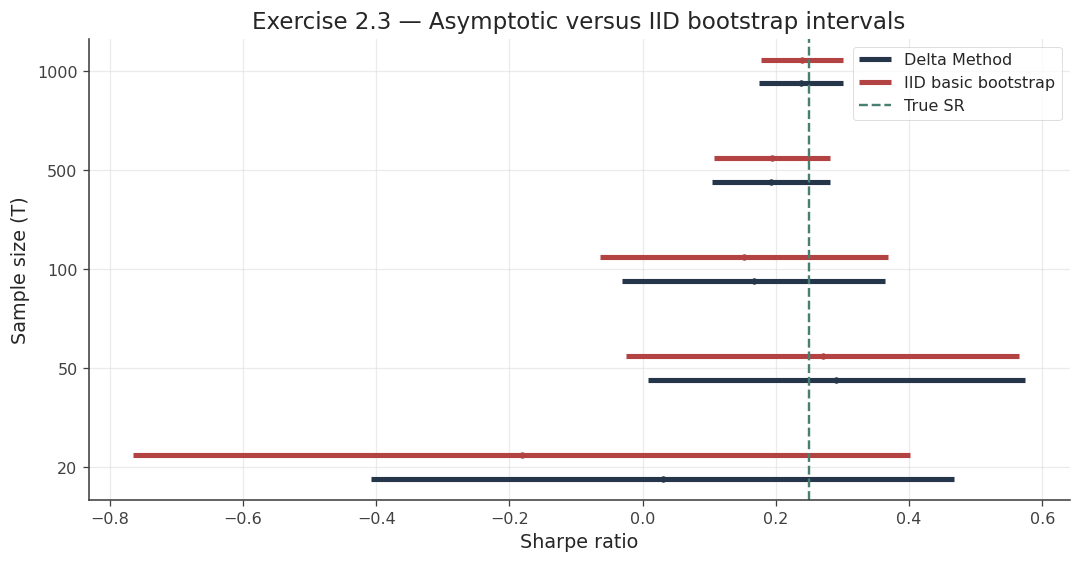

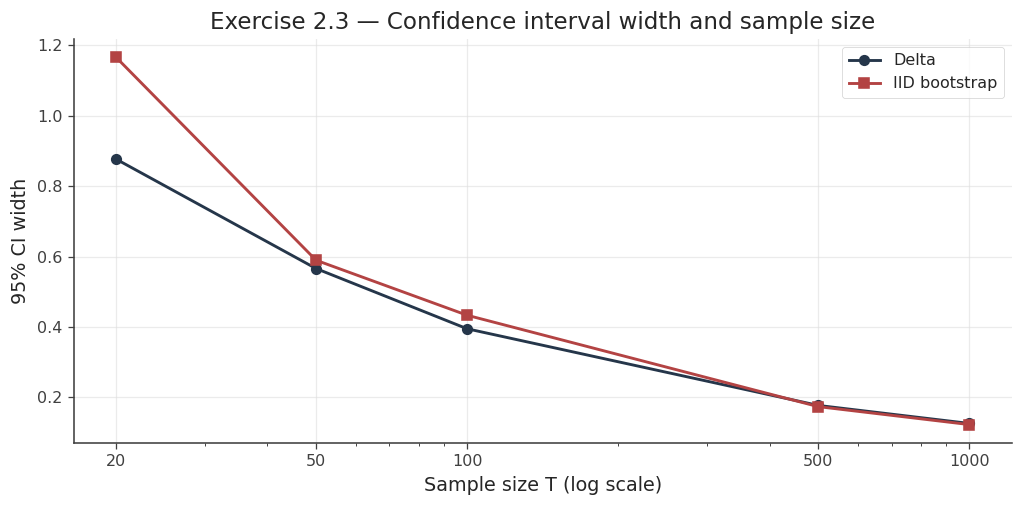

In [14]:
# Show both CI methods at every sample size, with slight vertical offsets.
fig, ax = plt.subplots(figsize=(9.5, 5))
pos = np.arange(len(T_values))
for j, (ci_group, offset, color, label) in enumerate([
        (ci_delta_by_t, -0.12, C_DARK, "Delta Method"),
        (ci_iid_by_t, 0.12, C_RED, "IID basic bootstrap")]):
    ax.hlines(pos + offset, ci_group[:, 0], ci_group[:, 1],
              color=color, lw=3.2, label=label)
    ax.scatter(ci_group.mean(axis=1), pos + offset, color=color, s=12)
ax.axvline(TRUE_SR, color=C_GREEN, ls="--", label="True SR")
ax.set(yticks=pos, yticklabels=T_values,
       xlabel="Sharpe ratio", ylabel="Sample size (T)",
       title="Exercise 2.3 — Asymptotic versus IID bootstrap intervals")
ax.legend()
plt.tight_layout()
plt.show()

widths_delta_t = ci_delta_by_t[:, 1] - ci_delta_by_t[:, 0]
widths_iid_t = ci_iid_by_t[:, 1] - ci_iid_by_t[:, 0]
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(T_values, widths_delta_t, "o-", color=C_DARK, lw=1.8, label="Delta")
ax.plot(T_values, widths_iid_t, "s-", color=C_RED, lw=1.8, label="IID bootstrap")
ax.set_xscale("log")
ax.set_xticks(T_values, labels=[str(n) for n in T_values])
ax.set(title="Exercise 2.3 — Confidence interval width and sample size",
       xlabel="Sample size T (log scale)", ylabel="95% CI width")
ax.legend()
plt.tight_layout()
plt.show()

***Graph interpretation:*** In the first graph we can see that for lower T values the confidence intervals for both methods are wider, even including negative results. 
In lower T values, the bootstrap method also shows more asymmetric results, as the Delta method imposes a normal symmetry, while bootstrap may better capture fatter tales or real asymmetry of the sample.
The width of both intervals decreases as the sample size increases, and mostly converge. With large numbers, normal approximation of the delta method is highly precise, and so does the bootstrap as the empiric distribution is gaussian.
in the second graph we can appreciate that as we increase the number of T, the width of the confidence interval deceases, and we can observe that the fall is almost linear when T gets larger. Which is consistent with the decrease rate mentioned earlier of T power of -1/2  

### Transition: why blocks?

The original data in Sections 1 and 2 are IID, so ordinary resampling is appropriate. However, resampling individual observations would disrupt their original ordering if the data were serially dependent. The TP6 therefore introduces a **non-overlapping block bootstrap** and first asks us to apply it to **the same IID data**. We will return to genuinely dependent observations in the AR(1) extension.


---

# 3. Dependent Data: The Block Bootstrap

## Overview and Motivation

The IID bootstrap introduced in Section 2 resamples individual observations independently. While appropriate for IID data, this approach does not preserve the temporal dependence structure of a time series, potentially leading to inaccurate standard errors and confidence intervals.

The **Block Bootstrap** addresses this limitation by resampling consecutive groups of observations rather than individual observations, thereby preserving dependence within each block.

Our analysis proceeds as follows:

1. **IID data — IID vs. Block Bootstrap:** We first apply both procedures to the same IID dataset used in Sections 1 and 2. Following the exercise instructions, we construct a 95% Block Bootstrap confidence interval and compare it with the IID Bootstrap interval. We then repeat the experiment across independent Monte Carlo samples to examine the stability of the results.

2. **Block length and serial dependence:** We discuss the role of block length $\ell$ and its trade-off between preserving serial dependence and retaining sufficient blocks for resampling. In practice, the **Autocorrelation Function (ACF)** provides useful guidance on the persistence of dependence and, consequently, the choice of block length, although it does not determine a unique optimal value.

3. **Extension to dependent data (Section 4):** We generate a stationary AR(1) process with $\phi=0.8$, examine its theoretical and empirical ACF and PACF, and compare IID and Block Bootstrap confidence intervals under serial dependence.

This approach allows us to evaluate the two bootstrap procedures first under independence, where the IID bootstrap is appropriate, and subsequently under dependence, where the Block Bootstrap becomes particularly relevant.

## 3.1 — Non-Overlapping Block Bootstrap ($B=2000$, $\ell=10$)

We implement the **Non-Overlapping Block Bootstrap (NBB)** on the original IID sample, following the procedure described in the exercise sheet.

Consider a time-ordered sample $X_1,\ldots,X_T$, with $T=k\ell$. The sample is partitioned into $k$ consecutive, non-overlapping blocks:

$$
\mathcal B_j=(X_{(j-1)\ell+1},\ldots,X_{j\ell}),
\qquad j=1,\ldots,k.
$$

For the baseline configuration:

$$
T=100,\qquad \ell=10,\qquad k=\frac{T}{\ell}=10.
$$

For each bootstrap replication $b=1,\ldots,B$, we independently draw $k$ block indices with replacement:

$$
J_1^{(b)},\ldots,J_k^{(b)}
\overset{\mathrm{iid}}{\sim}
\operatorname{Uniform}\{1,\ldots,k\}.
$$

The selected blocks are concatenated to construct the bootstrap sample:

$$
X^{*(b)}=\bigl(\mathcal B_{J_1^{(b)}},\ldots,
\mathcal B_{J_k^{(b)}}\bigr).
$$

Each bootstrap sample contains $T=k\ell=100$ observations, from which we compute:

$$
\widehat{SR}^{*(b)}_{BB}=
\frac{\overline X^{*(b)}_{BB}}
{\widehat\sigma^{*(b)}_{BB}}.
$$

We repeat this procedure $B=2000$ times to obtain the bootstrap distribution of the Sharpe ratio.

Unlike IID resampling, the Block Bootstrap preserves the original ordering of observations within each sampled block, although dependence across block boundaries is not preserved.


In [15]:
def nonoverlap_block_bootstrap_draws(sample, rng, B=2000, block_length=10):
    """Non-overlapping block bootstrap (NBB), as specified in TP6.

    The input is divided into k=n/block_length *consecutive* blocks.
    Each new dataset samples k whole blocks WITH replacement.
    """
    sample = np.asarray(sample)
    n = len(sample)
    if n % block_length != 0:
        raise ValueError("Sample size must be a multiple of block_length.")

    k = n // block_length
    blocks = sample.reshape(k, block_length)

    # (B,k) block labels -> (B,k,l) returns -> (B,n) datasets.
    block_indices = rng.integers(0, k, size=(B, k))
    resamples = blocks[block_indices].reshape(B, n)

    # Estimate the Sharpe ratio for every concatenated bootstrap sample.
    sr_draws = (np.mean(resamples, axis=1)
                / np.std(resamples, axis=1, ddof=0))
    return sr_draws

k = T // L
blocks_original = x.reshape(k, L)
sr_block_draws = nonoverlap_block_bootstrap_draws(x, rng_block, B=B,
                                                  block_length=L)
assert sr_block_draws.shape == (B,)

print(f"Block length l               = {L}")
print(f"Number of original blocks k = {k}")
print(f"Number of bootstrap estimates = {len(sr_block_draws)}")
print("Original blocks matrix shape:", blocks_original.shape)

Block length l               = 10
Number of original blocks k = 10
Number of bootstrap estimates = 2000
Original blocks matrix shape: (10, 10)


Block labels in one resample (0-based): [2 6 7 3 6 0 5 0 7 9]


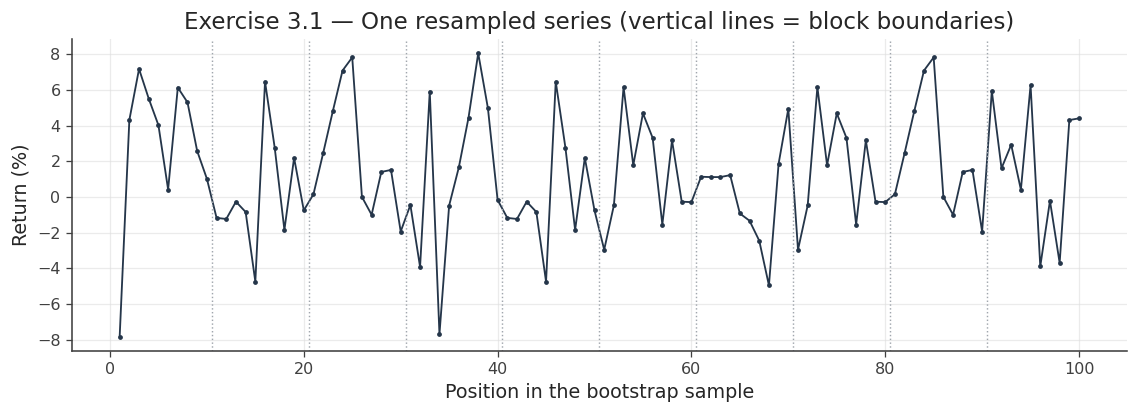

In [16]:
# Visual example: the first two original blocks stay internally ordered.
# A separate RNG prevents this illustration from affecting CI calculations.
rng_example = np.random.default_rng(458)
example_labels = rng_example.integers(0, k, size=k)
example_block_sample = blocks_original[example_labels].reshape(T)
print("Block labels in one resample (0-based):", example_labels)

fig, ax = plt.subplots(figsize=(10, 3.7))
ax.plot(np.arange(1, T+1), example_block_sample, color=C_DARK,
        lw=1.15, marker="o", ms=2)
for boundary in range(L, T, L):
    ax.axvline(boundary + 0.5, color=C_GRAY, ls=":", lw=0.9)
ax.set(title="Exercise 3.1 — One resampled series (vertical lines = block boundaries)",
       xlabel="Position in the bootstrap sample", ylabel="Return (%)")
plt.tight_layout()
plt.show()

## Exercise 3.2 — Construct the 95% basic block bootstrap CI

We apply exactly the same **basic bootstrap inversion** as in Section 2, now using the empirical quantiles of block bootstrap estimates:

$$
\boxed{CI_{BB,95\%}=
\left[2\widehat{SR}-q^{BB}_{0.975},\;
2\widehat{SR}-q^{BB}_{0.025}\right]}.
$$

Only the **resampling distribution** changes; the target parameter and the original estimator do not.


In [17]:
ci_block = basic_bootstrap_ci(sr_hat, sr_block_draws)
print(f"True SR                 = {TRUE_SR:.6f}")
print(f"Estimated SR            = {sr_hat:.6f}")
print(f"Delta Method CI         = {np.round(ci_delta, 6)}")
print(f"IID bootstrap CI        = {np.round(ci_iid, 6)}")
print(f"Block bootstrap CI      = {np.round(ci_block, 6)}")

True SR                 = 0.250000
Estimated SR            = 0.370854
Delta Method CI         = [0.168231 0.573477]
IID bootstrap CI        = [0.17033  0.578556]
Block bootstrap CI      = [0.24046  0.497856]


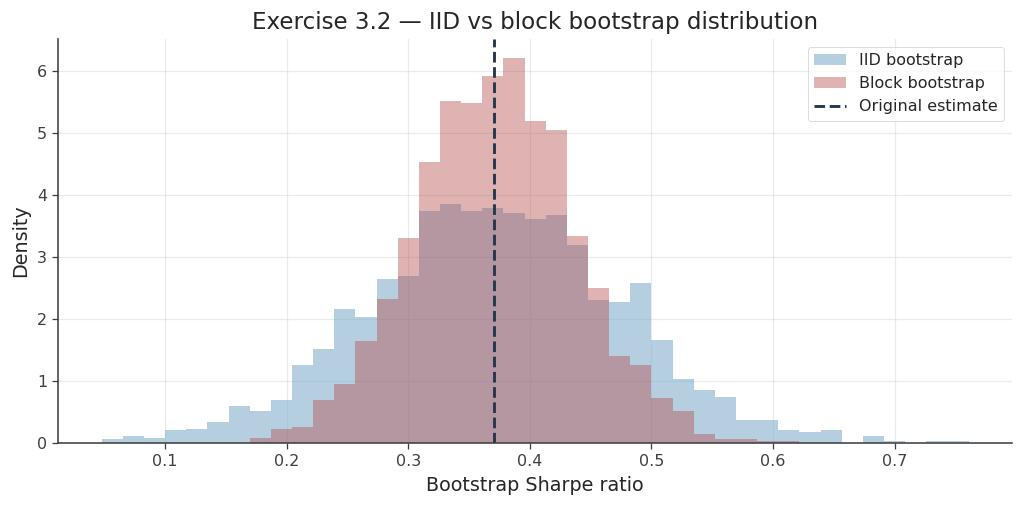

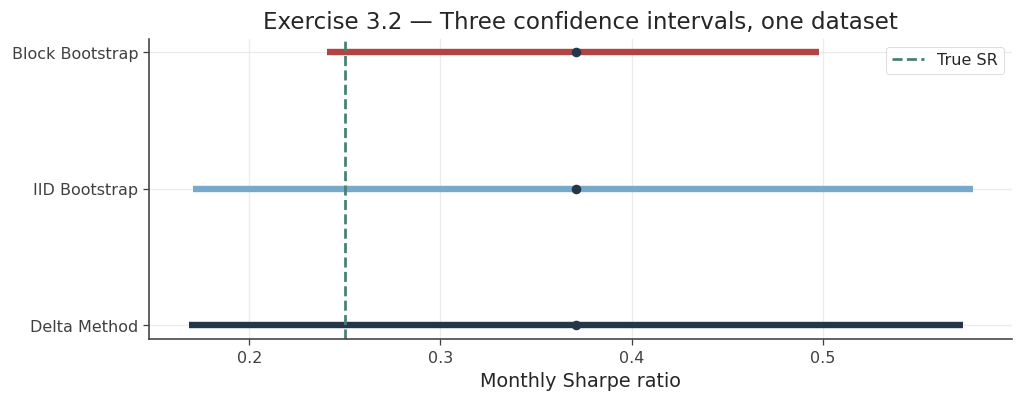

In [18]:
# Use common bin edges to make histogram shapes comparable.
common_bins = np.linspace(min(sr_iid_draws.min(), sr_block_draws.min()),
                          max(sr_iid_draws.max(), sr_block_draws.max()), 42)
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(sr_iid_draws, bins=common_bins, density=True,
        color=C_BLUE, alpha=0.55, label="IID bootstrap")
ax.hist(sr_block_draws, bins=common_bins, density=True,
        color=C_RED, alpha=0.4, label="Block bootstrap")
ax.axvline(sr_hat, color=C_DARK, ls="--", lw=1.8,
           label="Original estimate")
ax.set(title="Exercise 3.2 — IID vs block bootstrap distribution",
       xlabel="Bootstrap Sharpe ratio", ylabel="Density")
ax.legend()
plt.tight_layout()
plt.show()

# A compact visualization of the three 95% confidence intervals.
ci_groups = [ci_delta, ci_iid, ci_block]
ci_names = ["Delta Method", "IID Bootstrap", "Block Bootstrap"]
ci_colors = [C_DARK, C_BLUE, C_RED]
fig, ax = plt.subplots(figsize=(9, 3.6))
for i, (interval, color) in enumerate(zip(ci_groups, ci_colors)):
    ax.hlines(i, interval[0], interval[1], lw=4, color=color)
    ax.plot(sr_hat, i, "o", color=C_DARK, ms=5)
ax.axvline(TRUE_SR, color=C_GREEN, ls="--", lw=1.7, label="True SR")
ax.set(yticks=np.arange(3), yticklabels=ci_names,
       title="Exercise 3.2 — Three confidence intervals, one dataset",
       xlabel="Monthly Sharpe ratio")
ax.legend()
plt.tight_layout()
plt.show()

## Exercise 3.3 — Is the block interval wider? Repeat the experiment.

**One sample cannot establish a systematic conclusion.** To answer the TP's final question, we repeat the *entire* procedure $M=100$ times:

1. Generate a **new original IID Gaussian dataset** of length $T=100$.
2. On that dataset, generate $B=2000$ IID bootstrap Sharpe estimates and form its basic CI.
3. Separately generate $B=2000$ block bootstrap estimates ($\ell=10$) and form its basic CI.
4. Record CI widths and whether the **known** $SR=0.25$ is covered.

Let $W_j^{(m)}=U_j^{(m)}-L_j^{(m)}$ denote an interval width. Summarize:

$$
\overline W_j=\frac1M\sum_{m=1}^M W_j^{(m)},\quad
\widehat{\operatorname{coverage}}_j
=\frac1M\sum_{m=1}^M
\mathbf 1\{L_j^{(m)}\le SR\le U_j^{(m)}\}.
$$

Increasing $B$ stabilizes **bootstrap quantiles conditional on a dataset**. Increasing $M$ makes the **Monte Carlo comparison across datasets** more precise. Here the data are IID, so blocks are not expected to offer an inherent advantage; they may even be less efficient because only $k=10$ units are resampled.


In [19]:
M = 100  # Number of independently simulated original datasets (NOT bootstrap draws).
rng_mc_data = np.random.default_rng(905)
rng_mc_iid = np.random.default_rng(906)
rng_mc_block = np.random.default_rng(907)

widths_mc = np.empty((M, 2))
covered_mc = np.empty((M, 2), dtype=bool)

for m in range(M):
    # Stage 1: new outer (Monte Carlo) dataset.
    x_m = rng_mc_data.normal(MU, SIGMA, size=T)
    sr_m = sharpe_ratio(x_m)

    # Stage 2: two INNER bootstrap experiments, both using this same x_m.
    iid_m = iid_bootstrap_draws(x_m, rng_mc_iid, B=B)
    block_m = nonoverlap_block_bootstrap_draws(x_m, rng_mc_block,
                                                B=B, block_length=L)
    ci1 = basic_bootstrap_ci(sr_m, iid_m)
    ci2 = basic_bootstrap_ci(sr_m, block_m)

    widths_mc[m] = [np.ptp(ci1), np.ptp(ci2)]
    covered_mc[m] = [(ci1[0] <= TRUE_SR <= ci1[1]),
                     (ci2[0] <= TRUE_SR <= ci2[1])]

print(f"M = {M} independently simulated datasets; B = {B} per method/dataset")
print(f"Average IID CI width:        {widths_mc[:, 0].mean():.5f}")
print(f"Average block CI width:      {widths_mc[:, 1].mean():.5f}")
print(f"Fraction with wider block CI: {np.mean(widths_mc[:, 1] > widths_mc[:, 0]):.1%}")
print(f"Empirical IID coverage:      {covered_mc[:, 0].mean():.1%}")
print(f"Empirical block coverage:    {covered_mc[:, 1].mean():.1%}")

M = 100 independently simulated datasets; B = 2000 per method/dataset
Average IID CI width:        0.40538
Average block CI width:      0.37137
Fraction with wider block CI: 33.0%
Empirical IID coverage:      95.0%
Empirical block coverage:    89.0%


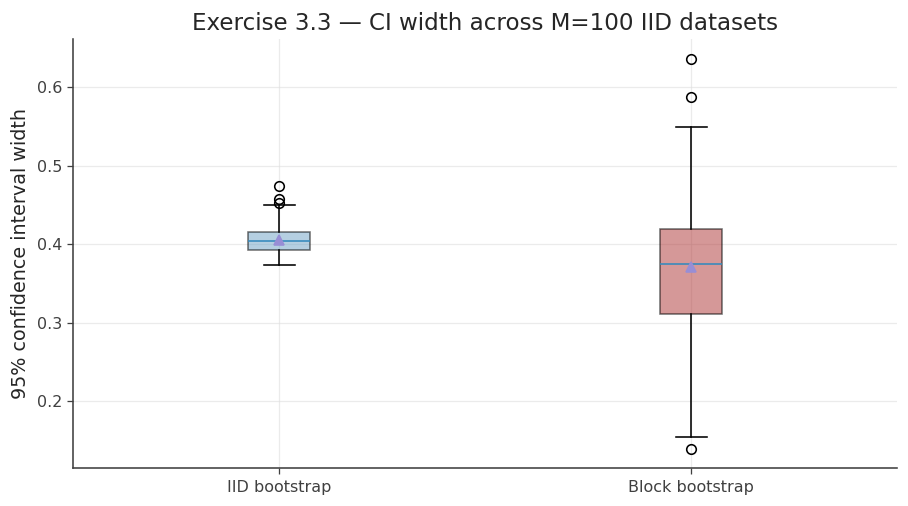

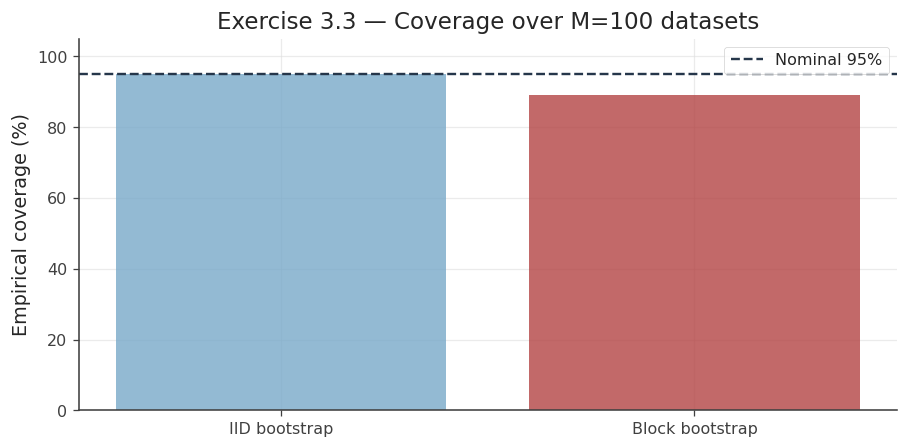

In [20]:
fig, ax = plt.subplots(figsize=(8, 4.5))
box = ax.boxplot([widths_mc[:, 0], widths_mc[:, 1]],
                 tick_labels=["IID bootstrap", "Block bootstrap"],
                 patch_artist=True, showmeans=True)
for patch, color in zip(box["boxes"], [C_BLUE, C_RED]):
    patch.set_facecolor(color)
    patch.set_alpha(0.55)
ax.set(title=f"Exercise 3.3 — CI width across M={M} IID datasets",
       ylabel="95% confidence interval width")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
coverage_mc_pct = 100*covered_mc.mean(axis=0)
ax.bar(["IID bootstrap", "Block bootstrap"], coverage_mc_pct,
       color=[C_BLUE, C_RED], alpha=0.8)
ax.axhline(95, color=C_DARK, ls="--", label="Nominal 95%")
ax.set(ylim=(0, 105), ylabel="Empirical coverage (%)",
       title=f"Exercise 3.3 — Coverage over M={M} datasets")
ax.legend()
plt.tight_layout()
plt.show()

### Interpretation

Across the 100 IID datasets, the Block Bootstrap produces **slightly narrower confidence intervals on average** (0.3714 vs 0.4054), although its intervals are wider in 33% of the simulations.

The boxplots also show that **Block Bootstrap interval widths are substantially more variable**, whereas IID Bootstrap widths are more stable.

Importantly, the IID Bootstrap achieves **95% empirical coverage**, compared with **89% for the Block Bootstrap**. Thus, ***narrower intervals do not necessarily imply better inference, particularly when the observations are IID and there is no temporal dependence to preserve***.


# 4. Extension — Bootstrap under Serial Dependence: An AR(1) Model

This section extends TP6 by investigating the performance of IID and Block Bootstrap confidence intervals when observations exhibit serial dependence. Unlike the previous experiment, we now simulate a stationary Gaussian AR(1) process with $\rho=0.8$.

We preserve the same $\mu=1$, $\operatorname{Var}(X_t)=16$, and hence the true $SR=0.25$, to isolate the effect of serial dependence:

$$
X_t-\mu=\rho(X_{t-1}-\mu)+\varepsilon_t,
\qquad \rho=0.8,
$$

$$
\varepsilon_t\overset{\mathrm{iid}}\sim N(0,\sigma_\varepsilon^2),
\qquad
\sigma_\varepsilon^2=\sigma^2(1-\rho^2)
=16(1-0.8^2)=5.76.
$$

A stochastic process is **weakly stationary** (or covariance-stationary) if its mean and variance are constant over time and its autocovariance depends only on the lag, rather than on the specific time period:

$$
E[X_t]=\mu,\qquad
\operatorname{Var}(X_t)=\sigma^2,\qquad
\operatorname{Cov}(X_t,X_{t-h})=\gamma(h).
$$

Since $|\rho|<1$, our AR(1) process is weakly stationary when initialized from its stationary distribution. In particular:

$$
E[X_t]=\mu=1,\qquad
\operatorname{Var}(X_t)=
\frac{\sigma_\varepsilon^2}{1-\rho^2}=16,
$$

with autocovariance function

$$
\gamma(h)=\sigma^2\rho^{|h|}
=16(0.8)^{|h|}.
$$

We use $T_{AR}=500$, $B_{AR}=2000$, and $\ell_{AR}=10$ to examine serial dependence more clearly, while keeping the main TP6 configuration ($T=100$) unchanged.

## 4.1 — Simulating a Weakly Stationary AR(1) Process

Starting from $X_0\sim N(\mu,16)$, independently of the innovations, the process is generated recursively as

$$
X_t=\mu+\rho(X_{t-1}-\mu)+\varepsilon_t.
$$

By construction, the simulated process has the same marginal mean and variance as the IID benchmark. The key difference lies in its **serial covariance structure**, which will be examined through the theoretical and empirical ACF and PACF before comparing the two bootstrap procedures.

AR(1) innovation variance = 5.7600
AR(1) estimated SR        = 0.233584 (true: 0.250000)


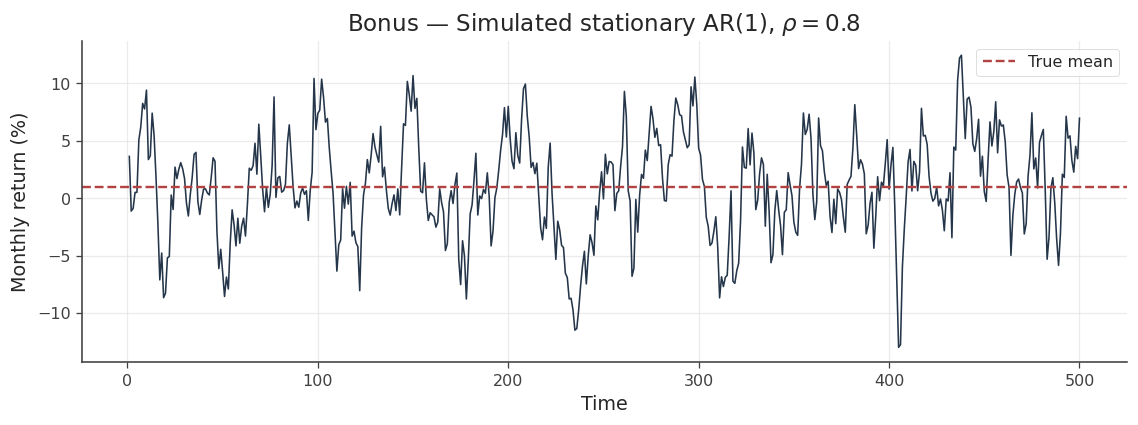

In [21]:
T_AR = 500
B_AR = 2000
RHO = 0.8
L_AR = 10

rng_ar_data = np.random.default_rng(789)
rng_ar_iid = np.random.default_rng(791)
rng_ar_block = np.random.default_rng(792)

def simulate_ar1(n, rng, mu=MU, sigma=SIGMA, rho=RHO):
    """Stationary Gaussian AR(1) with unconditional mean mu and sd sigma."""
    if not -1 < rho < 1:
        raise ValueError("Stationarity requires abs(rho) < 1")
    sample = np.empty(n)
    sample[0] = rng.normal(mu, sigma)  # Exact stationary initialization.
    innovation_sd = sigma * np.sqrt(1 - rho**2)
    shocks = rng.normal(0, innovation_sd, size=n-1)
    for t in range(1, n):
        sample[t] = mu + rho*(sample[t-1]-mu) + shocks[t-1]
    return sample

x_ar = simulate_ar1(T_AR, rng_ar_data)
sr_ar = sharpe_ratio(x_ar)

print(f"AR(1) innovation variance = {V*(1 - RHO**2):.4f}")
print(f"AR(1) estimated SR        = {sr_ar:.6f} (true: {TRUE_SR:.6f})")
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(np.arange(1, T_AR+1), x_ar, color=C_DARK, lw=1)
ax.axhline(MU, color=C_RED, ls="--", label="True mean")
ax.set(title=r"Bonus — Simulated stationary AR(1), $\rho=0.8$",
       xlabel="Time", ylabel="Monthly return (%)")
ax.legend()
plt.tight_layout()
plt.show()

## 4.2 — Theoretical vs Empirical ACF and PACF

To examine the serial dependence structure of the simulated AR(1) process, we compare its theoretical and empirical **Autocorrelation Function (ACF)** and **Partial Autocorrelation Function (PACF)**.

### Autocorrelation Function (ACF)

For a stationary AR(1), the theoretical autocorrelation at lag $h\geq 0$ is:

$$
\rho_X(h)=\frac{\gamma(h)}{\gamma(0)}=\rho^h=0.8^h.
$$

The empirical ACF is estimated as:

$$
\widehat{\rho}(h)=
\frac{\sum_{t=h+1}^{T}(X_t-\overline X)(X_{t-h}-\overline X)}
{\sum_{t=1}^{T}(X_t-\overline X)^2}.
$$

### Partial Autocorrelation Function (PACF)

The PACF measures the correlation between $X_t$ and $X_{t-h}$ after controlling for the intermediate lags. For an AR(1), the theoretical PACF satisfies:

$$
\operatorname{PACF}(h)=
\begin{cases}
\rho=0.8, & h=1,\\
0, & h\geq 2.
\end{cases}
$$

The empirical PACF at lag $h$ is obtained from the OLS regression:

$$
X_t-\overline X
=\sum_{j=1}^{h}\beta_j^{(h)}(X_{t-j}-\overline X)+u_t,
$$

where:

$$
\widehat{\operatorname{PACF}}(h)=\widehat{\beta}_h^{(h)}.
$$

The coefficients are estimated using NumPy's least-squares solver.


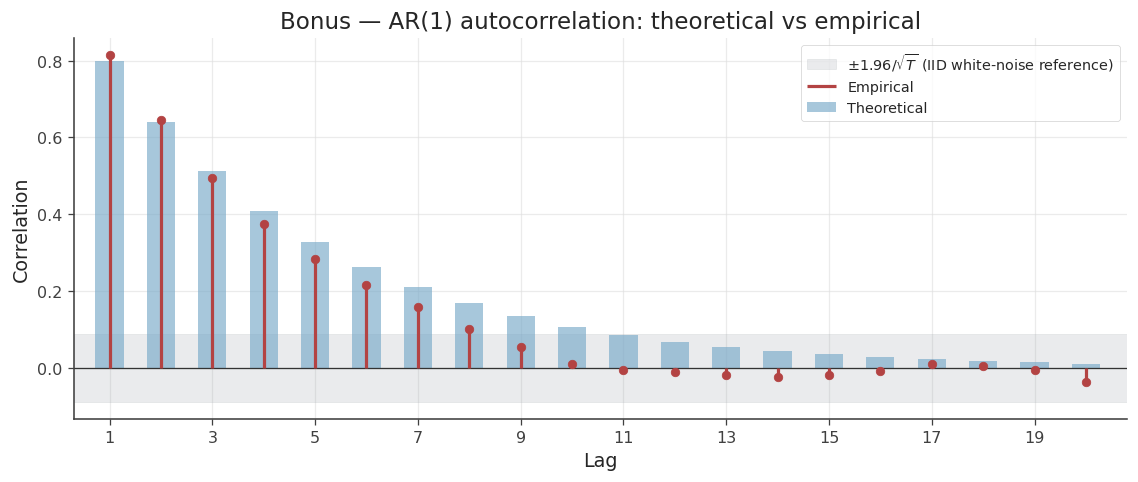

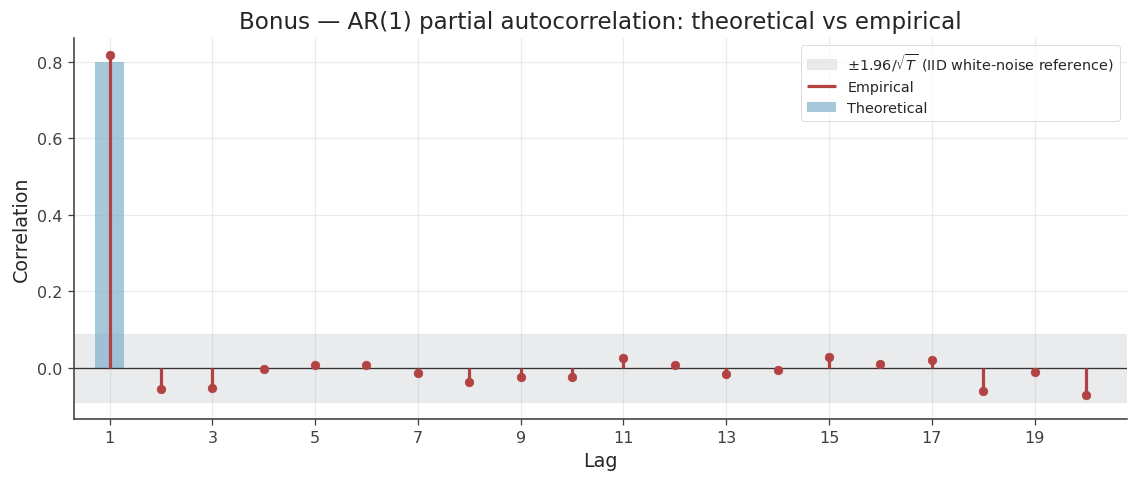

In [22]:
def sample_acf(sample, max_lag=20):
    """Biased-normalization sample ACF; useful for direct series comparison."""
    centered = sample - np.mean(sample)
    denom = np.dot(centered, centered)
    return np.array([
        np.dot(centered[:len(sample)-h], centered[h:]) / denom
        for h in range(max_lag + 1)
    ])

def sample_pacf_ols(sample, max_lag=20):
    """Partial autocorrelations via separate OLS regressions at each lag."""
    centered = sample - np.mean(sample)
    n = len(sample)
    pacf = np.ones(max_lag + 1)
    for lag in range(1, max_lag + 1):
        lagged = np.column_stack([
            centered[lag-j:n-j] for j in range(1, lag+1)
        ])
        pacf[lag] = np.linalg.lstsq(lagged, centered[lag:], rcond=None)[0][-1]
    return pacf

MAX_LAG = 20
lags = np.arange(1, MAX_LAG+1)
acf_theory = RHO**lags
pacf_theory = np.zeros(MAX_LAG)
pacf_theory[0] = RHO
acf_emp = sample_acf(x_ar, MAX_LAG)[1:]
pacf_emp = sample_pacf_ols(x_ar, MAX_LAG)[1:]
white_noise_reference = 1.96 / np.sqrt(T_AR)


def plot_theoretical_empirical_corr(lags, theoretical, empirical, title):
    """Theoretical bars with overlaid empirical stems."""
    fig, ax = plt.subplots(figsize=(10, 4.3))

    # Gray reference band
    ax.axhspan(
        -white_noise_reference, white_noise_reference,
        color=C_GRAY, alpha=0.22,
        label=r"$\pm1.96/\sqrt{T}$ (IID white-noise reference)"
    )

    # Theoretical ACF/PACF: light blue bars
    ax.bar(
        lags, theoretical, width=0.55,
        color=C_BLUE, alpha=0.65,
        label="Theoretical", zorder=2
    )

    # Empirical ACF/PACF: red stems superimposed on bars
    ax.vlines(
        lags, 0, empirical,
        color=C_RED, lw=2,
        label="Empirical", zorder=3
    )

    # Red markers at empirical values
    ax.scatter(
        lags, empirical,
        color=C_RED, s=28, zorder=4
    )

    ax.axhline(0, color="0.2", lw=0.8)

    ax.set(
        xlim=(0.3, max(lags)+0.8),
        xticks=np.arange(1, MAX_LAG+1, 2),
        xlabel="Lag",
        ylabel="Correlation",
        title=title
    )

    ax.legend(loc="upper right", fontsize=9)
    plt.tight_layout()
    plt.show()
plot_theoretical_empirical_corr(
    lags, acf_theory, acf_emp,
    "Bonus — AR(1) autocorrelation: theoretical vs empirical")
plot_theoretical_empirical_corr(
    lags, pacf_theory, pacf_emp,
    "Bonus — AR(1) partial autocorrelation: theoretical vs empirical")  

### Graphical Comparison

The plots display **theoretical correlations (light-blue bars)** alongside **empirical estimates (red stems and markers)**. The shaded $\pm 1.96/\sqrt{T}$ bands provide an approximate IID white-noise reference, rather than formal confidence bands for the AR(1) ACF.

This comparison illustrates the persistence of serial dependence and provides useful guidance for the subsequent discussion of block-length selection in the Block Bootstrap.

## 4.3 — What happens to autocorrelation after resampling?

To visualize the mechanism, form **one** IID bootstrap resample and **one** block bootstrap resample from the same AR(1) series, then compare their empirical ACFs to the original series and the theoretical ACF.

Observations remain consecutive **within** each resampled block, while dependence across block boundaries is interrupted. Therefore the block resample preserves some, but not all, temporal dependence. This is an illustration from one pair of resamples, not a repeated-sampling accuracy assessment.


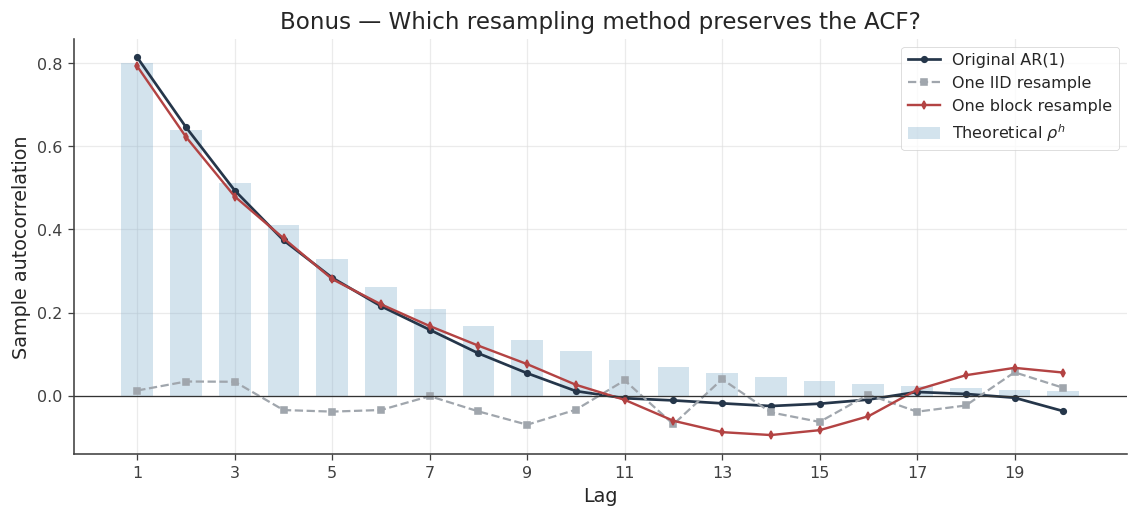

In [23]:
rng_acf_comparison = np.random.default_rng(790)
indices_one = rng_acf_comparison.integers(0, T_AR, size=T_AR)
x_iid_one = x_ar[indices_one]

blocks_ar = x_ar.reshape(T_AR//L_AR, L_AR)
labels_one = rng_acf_comparison.integers(0, T_AR//L_AR,
                                         size=T_AR//L_AR)
x_block_one = blocks_ar[labels_one].reshape(T_AR)

acf_original = sample_acf(x_ar, MAX_LAG)[1:]
acf_iid_one = sample_acf(x_iid_one, MAX_LAG)[1:]
acf_block_one = sample_acf(x_block_one, MAX_LAG)[1:]

fig, ax = plt.subplots(figsize=(10, 4.6))
ax.bar(lags, acf_theory, width=0.65, color=C_BLUE, alpha=0.32,
       label=r"Theoretical $\rho^h$")
ax.plot(lags, acf_original, "o-", ms=3.5, lw=1.7,
        color=C_DARK, label="Original AR(1)")
ax.plot(lags, acf_iid_one, "s--", ms=3.5, lw=1.4,
        color=C_GRAY, label="One IID resample")
ax.plot(lags, acf_block_one, "d-", ms=3.5, lw=1.5,
        color=C_RED, label="One block resample")
ax.axhline(0, color="0.2", lw=0.8)
ax.set(xticks=np.arange(1, MAX_LAG+1, 2),
       xlabel="Lag", ylabel="Sample autocorrelation",
       title="Bonus — Which resampling method preserves the ACF?")
ax.legend()
plt.tight_layout()
plt.show()

**Short theoretical note (long-run variance).** With dependent observations, the sampling variability of the sample mean depends not only on its marginal variance but also on autocovariances across time:

$$
\mathrm{LRV}=\gamma(0)+2\sum_{h\ge1}\gamma(h)
$$

IID resampling ignores these extra terms, whereas block resampling can reproduce part of their effect.

## 4.4 — IID vs block bootstrap under AR(1) dependence

We now repeat **exactly the same two bootstrap methods** from Sections 2 and 3, using the original AR(1) series $x_{AR}$ instead of the original IID data. The statistic, resampling algorithms, block length $\ell=10$, number of draws $B=2000$, and **basic confidence interval formula** remain unchanged.

- **IID bootstrap:** samples individual values, destroying their time ordering.
- **Block bootstrap:** samples consecutive groups of ten observations, preserving dependence within each group.

With $\rho=0.8$, even the block method may underestimate uncertainty because observations at newly joined block boundaries are no longer correlated as in the original series.


In [24]:
# Keep the original Gaussian-IID Delta interval as a reference (Section 1 function).
_, ci_delta_naive_ar, se_delta_naive_ar, *_ = gaussian_delta_ci(x_ar)

sr_iid_ar_draws = iid_bootstrap_draws(x_ar, rng_ar_iid, B=B_AR)
sr_block_ar_draws = nonoverlap_block_bootstrap_draws(
    x_ar, rng_ar_block, B=B_AR, block_length=L_AR)

ci_iid_ar = basic_bootstrap_ci(sr_ar, sr_iid_ar_draws)
ci_block_ar = basic_bootstrap_ci(sr_ar, sr_block_ar_draws)

print(f"AR(1) estimated SR           = {sr_ar:.6f}")
print(f"True SR                      = {TRUE_SR:.6f}")
print(f"Naive IID Delta CI           = {np.round(ci_delta_naive_ar, 5)}")
print(f"IID basic bootstrap CI       = {np.round(ci_iid_ar, 5)}")
print(f"Block basic bootstrap CI     = {np.round(ci_block_ar, 5)}")

AR(1) estimated SR           = 0.233584
True SR                      = 0.250000
Naive IID Delta CI           = [0.14474 0.32242]
IID basic bootstrap CI       = [0.14807 0.32543]
Block basic bootstrap CI     = [0.01511 0.43543]


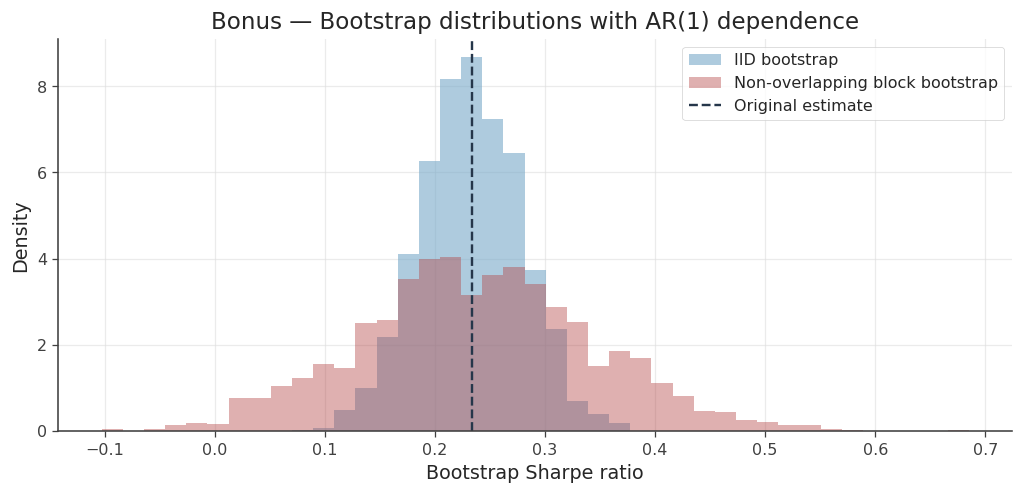

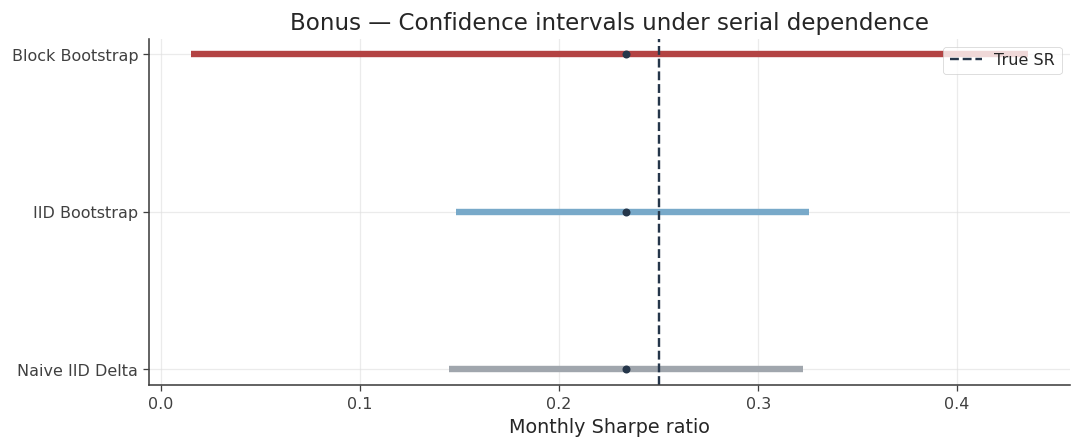

In [25]:
# Compare bootstrap sampling distributions using shared bin edges.
bins_ar = np.linspace(min(sr_iid_ar_draws.min(), sr_block_ar_draws.min()),
                      max(sr_iid_ar_draws.max(), sr_block_ar_draws.max()), 42)
fig, ax = plt.subplots(figsize=(9, 4.4))
ax.hist(sr_iid_ar_draws, bins=bins_ar, density=True, alpha=0.6,
        color=C_BLUE, label="IID bootstrap")
ax.hist(sr_block_ar_draws, bins=bins_ar, density=True, alpha=0.42,
        color=C_RED, label="Non-overlapping block bootstrap")
ax.axvline(sr_ar, color=C_DARK, ls="--", label="Original estimate")
ax.set(title="Bonus — Bootstrap distributions with AR(1) dependence",
       xlabel="Bootstrap Sharpe ratio", ylabel="Density")
ax.legend()
plt.tight_layout()
plt.show()

ci_ar_list = [ci_delta_naive_ar, ci_iid_ar, ci_block_ar]
ci_ar_labels = ["Naive IID Delta", "IID Bootstrap", "Block Bootstrap"]
ci_ar_colors = [C_GRAY, C_BLUE, C_RED]
fig, ax = plt.subplots(figsize=(9.5, 4))
for i, (ci, color) in enumerate(zip(ci_ar_list, ci_ar_colors)):
    ax.hlines(i, ci[0], ci[1], color=color, lw=4)
    ax.plot(sr_ar, i, "o", color=C_DARK, ms=4)
ax.axvline(TRUE_SR, color=C_DARK, ls="--", label="True SR")
ax.set(yticks=np.arange(3), yticklabels=ci_ar_labels,
       xlabel="Monthly Sharpe ratio",
       title="Bonus — Confidence intervals under serial dependence")
ax.legend()
plt.tight_layout()
plt.show()

### Interpretation and limitations

- **IID bootstrap** destroys temporal dependence; it is appropriate for the IID experiment in Section 3, but it cannot preserve the autocorrelation present in the AR(1) series.
- **Block bootstrap** preserves some local dependence within blocks, as illustrated by the ACF comparison above. However, it does not maintain the correlation across the boundaries between sampled blocks, so $\ell=10$ is not automatically sufficient when $\rho=0.8$.
- **How to interpret the intervals:** compare both the bootstrap distributions and CI widths in the original plots. A wider confidence interval reflects greater estimated sampling uncertainty; it does not, by itself, prove better coverage. The AR(1) results shown here are from **one original series**, not a Monte Carlo coverage experiment.




In [26]:

# 4.5 — Monte Carlo coverage under AR(1) dependence

M_AR = 500
rng_mc_ar = np.random.default_rng(1207)
rng_mc_iid = np.random.default_rng(1208)
rng_mc_block = np.random.default_rng(1209)

coverage_ar = np.zeros((M_AR, 3), dtype=bool)
widths_ar = np.zeros((M_AR, 3))

for m in range(M_AR):
    # Generate a new independent AR(1) dataset
    sample = simulate_ar1(T_AR, rng_mc_ar)
    sr = sharpe_ratio(sample)

    # Three confidence intervals on the SAME dataset
    ci_delta = gaussian_delta_ci(sample)[1]

    ci_iid = basic_bootstrap_ci(
        sr, iid_bootstrap_draws(sample, rng_mc_iid, B_AR)
    )

    ci_block = basic_bootstrap_ci(
        sr, nonoverlap_block_bootstrap_draws(
            sample, rng_mc_block, B_AR, L_AR
        )
    )

    for j, ci in enumerate([ci_delta, ci_iid, ci_block]):
        widths_ar[m, j] = np.ptp(ci)
        coverage_ar[m, j] = ci[0] <= TRUE_SR <= ci[1]

methods = ["Naive Delta", "IID Bootstrap", "Block Bootstrap"]

for j, name in enumerate(methods):
    print(f"{name}:")
    print(f"  Mean width: {widths_ar[:, j].mean():.4f}")
    print(f"  Coverage:   {coverage_ar[:, j].mean():.1%}")


Naive Delta:
  Mean width: 0.1790
  Coverage:   49.0%
IID Bootstrap:
  Mean width: 0.1791
  Coverage:   48.6%
Block Bootstrap:
  Mean width: 0.4140
  Coverage:   87.0%


### 4.5 — Interpretation

Under positive serial dependence, both the naive Gaussian-IID Delta Method and the IID Bootstrap underestimate the sampling uncertainty of the Sharpe ratio, resulting in substantially narrower confidence intervals.

The Monte Carlo experiment confirms that narrower intervals do not necessarily imply better inference: both IID-based approaches exhibit severe undercoverage relative to the nominal 95% confidence level.

The Block Bootstrap substantially improves empirical coverage by preserving within-block dependence. However, coverage remains below 95%, suggesting that blocks of length 10 may be insufficient to capture the strong persistence of the AR(1) process with \(\rho=0.8\).

<a style='text-decoration:none;line-height:16px;display:flex;color:#5B5B62;padding:10px;justify-content:end;' href='https://deepnote.com?utm_source=created-in-deepnote-cell&projectId=6e455b5e-d088-4e55-ac18-c9dcfb88e6e3' target="_blank">

Created in <span style='font-weight:600;margin-left:4px;'>Deepnote</span></a>